In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns 

In [2]:
df = pd.read_csv("telecom_clientes.csv")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   Churn             7043 non-null   str    
 2   Gender            7043 non-null   str    
 3   SeniorCitizen     7043 non-null   int64  
 4   Partner           7043 non-null   str    
 5   Dependents        7043 non-null   str    
 6   Tenure            7043 non-null   int64  
 7   PhoneService      7043 non-null   str    
 8   MultipleLines     7043 non-null   str    
 9   InternetService   7043 non-null   str    
 10  OnlineSecurity    7043 non-null   str    
 11  OnlineBackup      7043 non-null   str    
 12  DeviceProtection  7043 non-null   str    
 13  TechSupport       7043 non-null   str    
 14  StreamingTV       7043 non-null   str    
 15  StreamingMovies   7043 non-null   str    
 16  Contract          7043 non-null   str    
 17  Paperl

In [4]:
#Buscar valores vacíos
valores_vacios = (df['ChargesTotal'] == ' ').sum()

In [5]:
valores_vacios

np.int64(0)

In [6]:
#Buscar valores nulos
df.isna().sum()

customerID           0
Churn                0
Gender               0
SeniorCitizen        0
Partner              0
Dependents           0
Tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
ChargesMonthly       0
ChargesTotal        11
CuentasDiarias       0
dtype: int64

In [7]:
#Eliminar valores nulos
df = df.dropna()

In [8]:
#Comprobar que fueron eliminados
df.isna().sum()

customerID          0
Churn               0
Gender              0
SeniorCitizen       0
Partner             0
Dependents          0
Tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
ChargesMonthly      0
ChargesTotal        0
CuentasDiarias      0
dtype: int64

In [9]:
#Porcentaje de clientes que hicieron churn
proporcion_evasion = df['Churn'].value_counts(normalize=True).to_frame()

In [10]:
proporcion_evasion

,proportion
Churn,
no,0.734215
yes,0.265785


In [11]:
round(proporcion_evasion.loc['yes'],2)

proportion    0.27
Name: yes, dtype: float64

In [12]:
tasa_pago = pd.crosstab(df["Gender"], df["Churn"], normalize=True)
    
tasa_pago.sort_values(by='yes', ascending=True, inplace=True)

In [13]:
tasa_pago.info()

<class 'pandas.DataFrame'>
Index: 2 entries, male to female
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   no      2 non-null      float64
 1   yes     2 non-null      float64
dtypes: float64(2)
memory usage: 59.0 bytes


In [14]:
tasa_pago.index

Index(['male', 'female'], dtype='str', name='Gender')

In [15]:
tasa_pago['yes']

Gender
male      0.132253
female    0.133532
Name: yes, dtype: float64

In [16]:
tasa_pago = pd.crosstab(df['Gender'], df["Churn"], normalize='index')
    
tasa_pago.sort_values(by='yes', ascending=True, inplace=True)

In [17]:
tasa_pago.info()

<class 'pandas.DataFrame'>
Index: 2 entries, male to female
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   no      2 non-null      float64
 1   yes     2 non-null      float64
dtypes: float64(2)
memory usage: 59.0 bytes


In [18]:
tasa_pago

Churn,no,yes
Gender,,
male,0.737954,0.262046
female,0.730405,0.269595


In [19]:
tasa_pago.index

Index(['male', 'female'], dtype='str', name='Gender')

In [20]:
for categoria in tasa_pago.index:
    tasa_categoria = tasa_pago.loc[categoria, 'yes']

    print(tasa_categoria)

0.26204564666103125
0.2695951765719208


In [21]:
df['SeniorCitizen'] = np.where(df['SeniorCitizen'] == 1, 'Mayor que 65', 'Menor que 65')

In [22]:
df['SeniorCitizen']

0       Menor que 65
1       Menor que 65
2       Menor que 65
3       Mayor que 65
4       Mayor que 65
            ...     
7038    Menor que 65
7039    Menor que 65
7040    Menor que 65
7041    Menor que 65
7042    Menor que 65
Name: SeniorCitizen, Length: 7032, dtype: str

In [23]:
servicios = df[['PhoneService', 'MultipleLines',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies']]

servicios_columnas = ['PhoneService', 
                      'MultipleLines', 
                      'OnlineSecurity', 
                      'OnlineBackup', 
                      'DeviceProtection',
                       'TechSupport', 
                       'StreamingTV', 
                       'StreamingMovies']

servicios[servicios_columnas] = np.where(servicios[servicios_columnas] == 'yes', 1, 0)

servicios['InternetService'] = np.where((df['InternetService'] == 'dsl') | (df['InternetService'] == 'fiber optic'), 1, 0)

servicios['Churn'] = np.where(df['Churn'] == 'yes', 1, 0)

servicios_columnas.append('InternetService')

servicios['numero_servicios'] = servicios[servicios_columnas].sum(axis=1)

In [24]:
servicios

,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetService,Churn,numero_servicios
0,1,0,0,1,0,1,1,0,1,0,5
1,1,1,0,0,0,0,0,1,1,0,4
2,1,0,0,0,1,0,0,0,1,1,3
3,1,0,0,1,1,0,1,1,1,1,6
4,1,0,0,0,0,1,1,0,1,1,4
...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,0,0,1,0,0,1,0,4
7039,1,1,0,0,0,0,0,1,1,1,4
7040,1,0,0,1,0,0,0,0,1,0,3
7041,1,0,1,0,1,1,0,1,1,0,6


<Axes: xlabel='numero_servicios', ylabel='Count'>

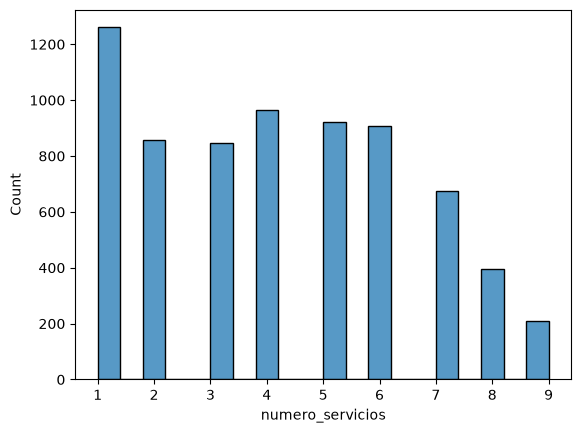

In [25]:
sns.histplot(data=servicios['numero_servicios'])


In [26]:
churn_servicios = pd.crosstab(servicios['numero_servicios'], servicios['Churn'], normalize='index')

churn_servicios.rename({0:'No', 1:'Yes'}, axis=1, inplace=True)

In [27]:
churn_servicios

Churn,No,Yes
numero_servicios,,
1,0.890476,0.109524
2,0.689615,0.310385
3,0.550827,0.449173
4,0.635233,0.364767
5,0.686211,0.313789
6,0.743929,0.256071
7,0.774481,0.225519
8,0.875949,0.124051
9,0.947115,0.052885


In [28]:
servicios_tenure = pd.DataFrame()
servicios_tenure['n_servicios'] = servicios['numero_servicios']
servicios_tenure['tenure'] = df['Tenure']
servicios_tenure['churn'] = df['Churn']


corr_servicios_tenure = servicios_tenure[['tenure', 'n_servicios']].corr()

In [29]:
servicios_tenure = servicios_tenure.sort_values(by='churn', ascending=True)

In [30]:
corr_servicios_tenure.iloc[0,1]

np.float64(0.4743698007260296)

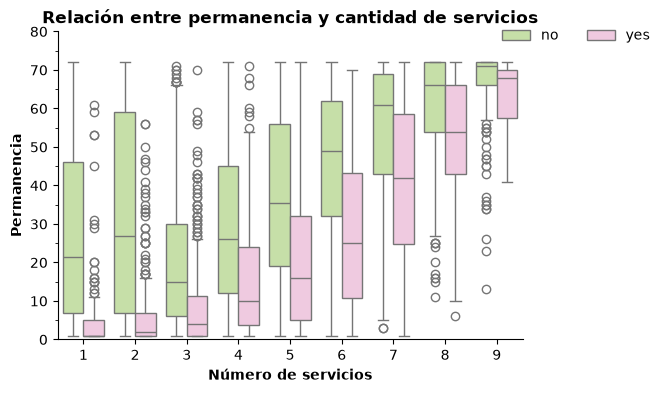

In [31]:
fig, ax  = plt.subplots(figsize=(6,4))

sns.boxplot(servicios_tenure, x='n_servicios', y='tenure', hue='churn', palette='PiYG_r', ax=ax)

ax.set_title('Relación entre permanencia y cantidad de servicios', fontsize=12, fontweight='bold')
ax.set_xlabel('Número de servicios', fontsize=10, fontweight='bold')
ax.set_ylabel('Permanencia', fontsize=10, fontweight='bold')

ax.set_ylim(0,80)
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))

ax.legend(loc='upper right', bbox_to_anchor=(1.30,1.05), ncols=2, frameon=False)

ax.spines[['top', 'right']].set_visible(False)

plt.show()

In [32]:
facturacion_permanencia = pd.DataFrame()

facturacion_permanencia['total_facturado'] = df['ChargesTotal']
facturacion_permanencia['tenure'] = df['Tenure']

facturacion_permanencia.corr()

,total_facturado,tenure
total_facturado,1.00000,0.82588
tenure,0.82588,1.00000


In [33]:
facturacion_permanencia['churn'] = df['Churn']

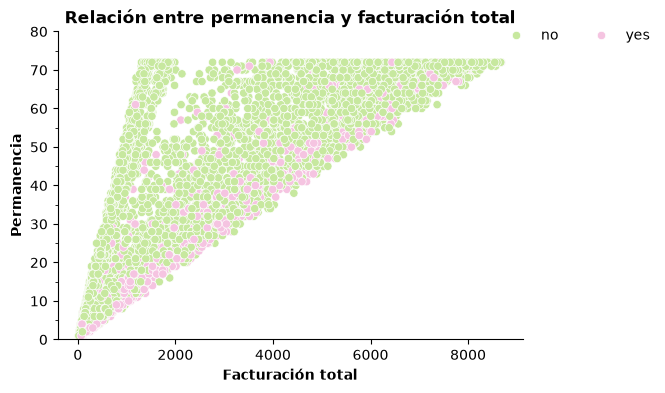

In [34]:
fig, ax  = plt.subplots(figsize=(6,4))

sns.scatterplot(facturacion_permanencia, x='total_facturado', y='tenure', hue='churn', palette='PiYG_r', ax=ax)

ax.set_title('Relación entre permanencia y facturación total', fontsize=12, fontweight='bold')
ax.set_xlabel('Facturación total', fontsize=10, fontweight='bold')
ax.set_ylabel('Permanencia', fontsize=10, fontweight='bold')

ax.set_ylim(0,80)
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))

ax.legend(loc='upper right', bbox_to_anchor=(1.30,1.05), ncols=2, frameon=False)

ax.spines[['top', 'right']].set_visible(False)

plt.show()

In [35]:
df['N_servicios'] = servicios['numero_servicios']

In [36]:
df = df.drop(columns='customerID')

In [37]:
col_categoricas = df.select_dtypes(include='object').columns

C:\Users\JIMENA\AppData\Local\Temp\ipykernel_11956\3074538577.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col_categoricas = df.select_dtypes(include='object').columns


In [38]:
col_categoricas

Index(['Churn', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='str')

In [39]:
for col in col_categoricas:
    print(f'{col}: {df[col].unique()}')

Churn: <ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str
Gender: <ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
SeniorCitizen: <ArrowStringArray>
['Menor que 65', 'Mayor que 65']
Length: 2, dtype: str
Partner: <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
Dependents: <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
PhoneService: <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
MultipleLines: <ArrowStringArray>
['no', 'yes', 'no phone service']
Length: 3, dtype: str
InternetService: <ArrowStringArray>
['dsl', 'fiber optic', 'no internet service']
Length: 3, dtype: str
OnlineSecurity: <ArrowStringArray>
['no', 'yes', 'no internet service']
Length: 3, dtype: str
OnlineBackup: <ArrowStringArray>
['yes', 'no', 'no internet service']
Length: 3, dtype: str
DeviceProtection: <ArrowStringArray>
['no', 'yes', 'no internet service']
Length: 3, dtype: str
TechSupport: <ArrowStringArray>
['yes', 'no', 'no internet service']
Length: 3, dtype: str
StreamingTV: <

In [40]:
from scipy.stats import chi2_contingency

In [41]:
"""
Función que calcula el coeficiente de Cramer
Utilizamos el coeficiente corregido de V-Cramer, ya que el no corregido puede
introducir sesgos
"""
def v_cramer_corregido(col1, col2):
  tabla_cont = pd.crosstab(col1, col2)
  estadistico_chi2 = chi2_contingency(tabla_cont)[0]
  n = tabla_cont.sum().sum()
  estadistico_phi2 = estadistico_chi2 / n
  renglon, columnas = tabla_cont.shape
  phi2corr = max(0, estadistico_phi2 - ((columnas-1)*(renglon-1))/(n-1))
  renglon_corr = renglon - ((renglon-1)**2)/(n-1)
  columnas_corr = columnas - ((columnas-1)**2)/(n-1)
  return np.sqrt(phi2corr / min((columnas_corr-1), (renglon_corr-1)))
     

In [42]:
#Creamos la matriz que guardará los coeficientes de V de Cramer
v_cramer_matrix = pd.DataFrame(index=col_categoricas, columns=col_categoricas)
v_cramer_matrix

,Churn,Gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
Churn,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Partner,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PhoneService,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineBackup,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:
#Guardamos en la matriz anterior el coeficiente para cada par de variables categóricas
for col1 in col_categoricas:
    for col2 in col_categoricas:
      v_cramer_matrix.loc[col1, col2] = v_cramer_corregido(df[col1], df[col2])
v_cramer_matrix

,Churn,Gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
Churn,0.999636,0.0,0.149641,0.149194,0.162351,0.0,0.036313,0.32149,0.346607,0.291435,0.280672,0.342115,0.229541,0.230101,0.409242,0.190768,0.302276
Gender,0.0,0.999716,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
SeniorCitizen,0.149641,0.0,0.999477,0.011506,0.209805,0.0,0.145768,0.264401,0.210067,0.181778,0.182065,0.223088,0.184662,0.187948,0.142177,0.15542,0.194411
Partner,0.149194,0.0,0.011506,0.999715,0.451833,0.013371,0.143323,0.0,0.150982,0.152383,0.165056,0.126398,0.135653,0.128819,0.294869,0.006676,0.162568
Dependents,0.162351,0.0,0.209805,0.451833,0.99966,0.0,0.018489,0.177625,0.192257,0.160282,0.155045,0.179958,0.144539,0.139034,0.241117,0.109173,0.147969
PhoneService,0.0,0.0,0.0,0.013371,0.0,0.999186,0.999929,0.451973,0.174869,0.171606,0.171077,0.175564,0.179585,0.176155,0.0,0.010974,0.0
MultipleLines,0.036313,0.0,0.145768,0.143323,0.018489,0.999929,1.0,0.396438,0.228862,0.244527,0.245806,0.229346,0.261451,0.261932,0.078781,0.165678,0.165773
InternetService,0.32149,0.0,0.264401,0.0,0.177625,0.451973,0.396438,1.0,0.724274,0.707076,0.707006,0.722715,0.717098,0.715862,0.205381,0.377616,0.311601
OnlineSecurity,0.346607,0.0,0.210067,0.150982,0.192257,0.174869,0.228862,0.724274,1.0,0.718311,0.717167,0.732944,0.707679,0.708124,0.30038,0.341033,0.303383
OnlineBackup,0.291435,0.0,0.181778,0.152383,0.160282,0.171606,0.244527,0.707076,0.718311,1.0,0.719013,0.719712,0.71459,0.71362,0.257493,0.320215,0.281034


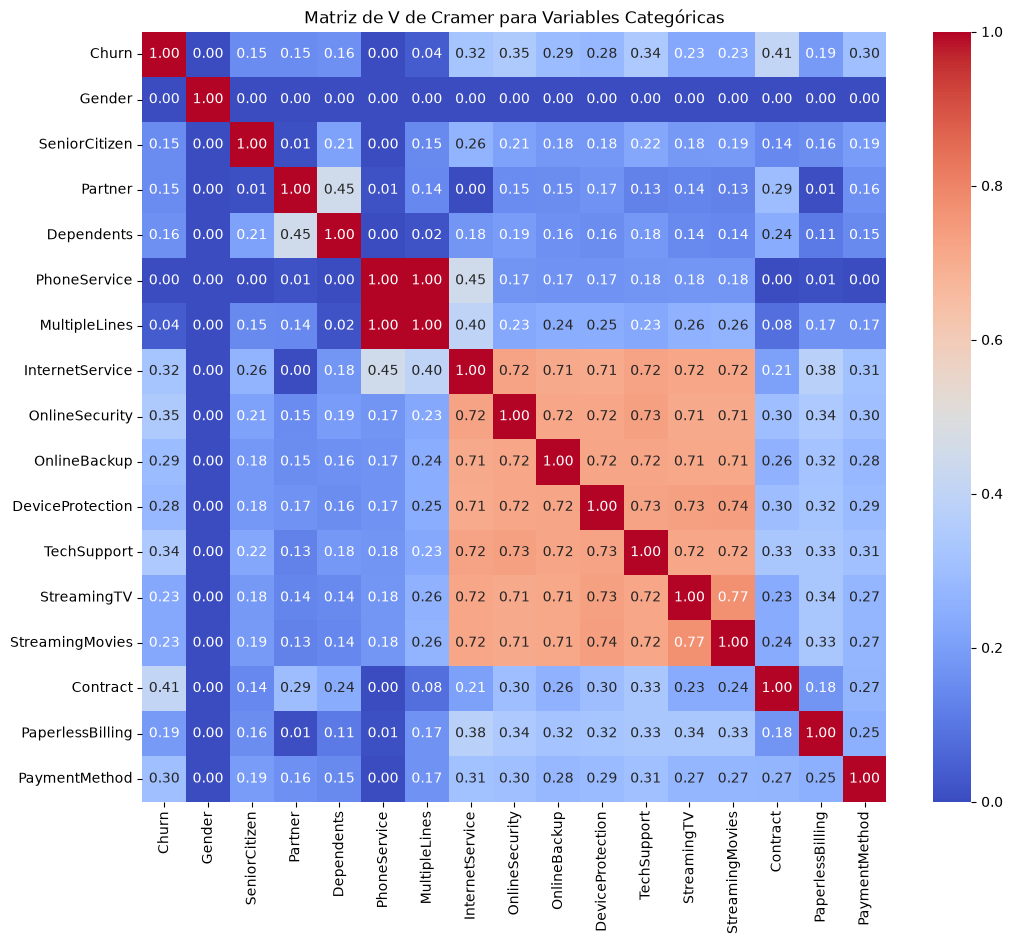

In [44]:
#Gráfico de la matriz de Cramer
plt.figure(figsize=(12, 10))
sns.heatmap(v_cramer_matrix.astype(float), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de V de Cramer para Variables Categóricas")
plt.show()

In [45]:
#Filtro para elegir las variables categóricas que tienen una relación más fuerte con Churn
target_var = 'Churn'
v_relevantes = v_cramer_matrix.index[abs(v_cramer_matrix[target_var]) >= 0.20].tolist()
v_relevantes

['Churn',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaymentMethod']

In [46]:
"""
Creamos otra matriz con solo los coeficientes de las variables
más fuertemente relacionadas con Churn
"""
v_filtrada = v_cramer_matrix.loc[v_relevantes, v_relevantes]
v_filtrada
     

,Churn,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaymentMethod
Churn,0.999636,0.32149,0.346607,0.291435,0.280672,0.342115,0.229541,0.230101,0.409242,0.302276
InternetService,0.32149,1.0,0.724274,0.707076,0.707006,0.722715,0.717098,0.715862,0.205381,0.311601
OnlineSecurity,0.346607,0.724274,1.0,0.718311,0.717167,0.732944,0.707679,0.708124,0.30038,0.303383
OnlineBackup,0.291435,0.707076,0.718311,1.0,0.719013,0.719712,0.71459,0.71362,0.257493,0.281034
DeviceProtection,0.280672,0.707006,0.717167,0.719013,1.0,0.726368,0.733436,0.736063,0.296083,0.285581
TechSupport,0.342115,0.722715,0.732944,0.719712,0.726368,1.0,0.716151,0.716373,0.330192,0.305319
StreamingTV,0.229541,0.717098,0.707679,0.71459,0.733436,0.716151,1.0,0.771132,0.234757,0.272303
StreamingMovies,0.230101,0.715862,0.708124,0.71362,0.736063,0.716373,0.771132,1.0,0.238233,0.273242
Contract,0.409242,0.205381,0.30038,0.257493,0.296083,0.330192,0.234757,0.238233,1.0,0.265958
PaymentMethod,0.302276,0.311601,0.303383,0.281034,0.285581,0.305319,0.272303,0.273242,0.265958,1.0


In [47]:
"""
Creamos una máscara booleana para ocultar el triángulo superior
de la matriz anterior
"""
mascara = np.triu(np.ones_like(v_filtrada, dtype=bool))

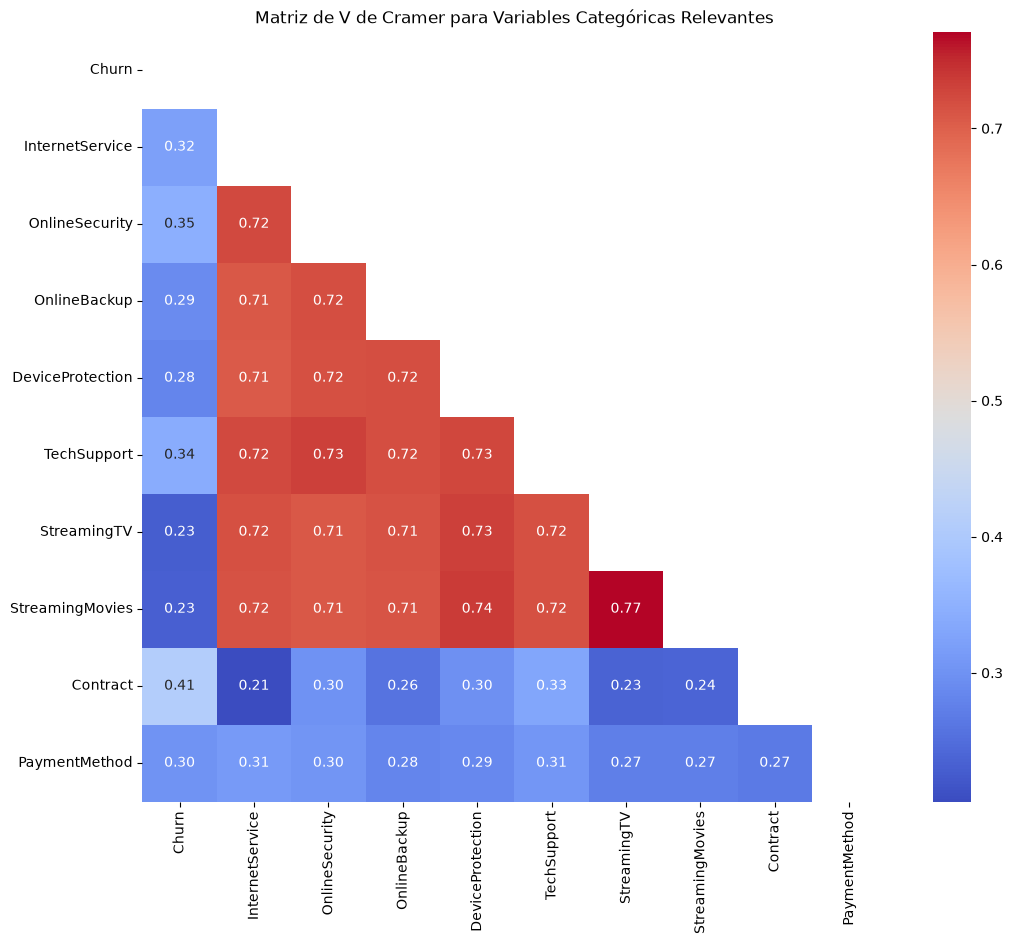

In [48]:
#Gráfico de la matriz filtrada
plt.figure(figsize=(12, 10))
sns.heatmap(v_filtrada.astype(float), annot=True, cmap='coolwarm', fmt=".2f", mask=mascara)
plt.title("Matriz de V de Cramer para Variables Categóricas Relevantes")
plt.show()

In [49]:
"""
Seleccionamos las variables numéricas y luego calculamos la correlación entre
las variables númericas más la variable objetivo churn
"""
variables_numericas = df.select_dtypes(include=['number'])
variables_numericas['Churn'] = df['Churn'].replace({'no': 0, 'yes': 1})
df_corr = variables_numericas.corr()
print('\t\tMatriz de Correlación entre variables numéricas independientes y churn\t\t')
print(df_corr)

		Matriz de Correlación entre variables numéricas independientes y churn		
                  Tenure  ChargesMonthly  ChargesTotal  CuentasDiarias  \
Tenure          1.000000        0.246862      0.825880        0.246862   
ChargesMonthly  0.246862        1.000000      0.651065        1.000000   
ChargesTotal    0.825880        0.651065      1.000000        0.651065   
CuentasDiarias  0.246862        1.000000      0.651065        1.000000   
N_servicios     0.474370        0.851408      0.777388        0.851408   
Churn          -0.354049        0.192858     -0.199484        0.192858   

                N_servicios     Churn  
Tenure             0.474370 -0.354049  
ChargesMonthly     0.851408  0.192858  
ChargesTotal       0.777388 -0.199484  
CuentasDiarias     0.851408  0.192858  
N_servicios        1.000000 -0.019644  
Churn             -0.019644  1.000000  


In [80]:
mascara_numericas = np.triu(np.ones_like(df_corr, dtype=bool))

<Axes: >

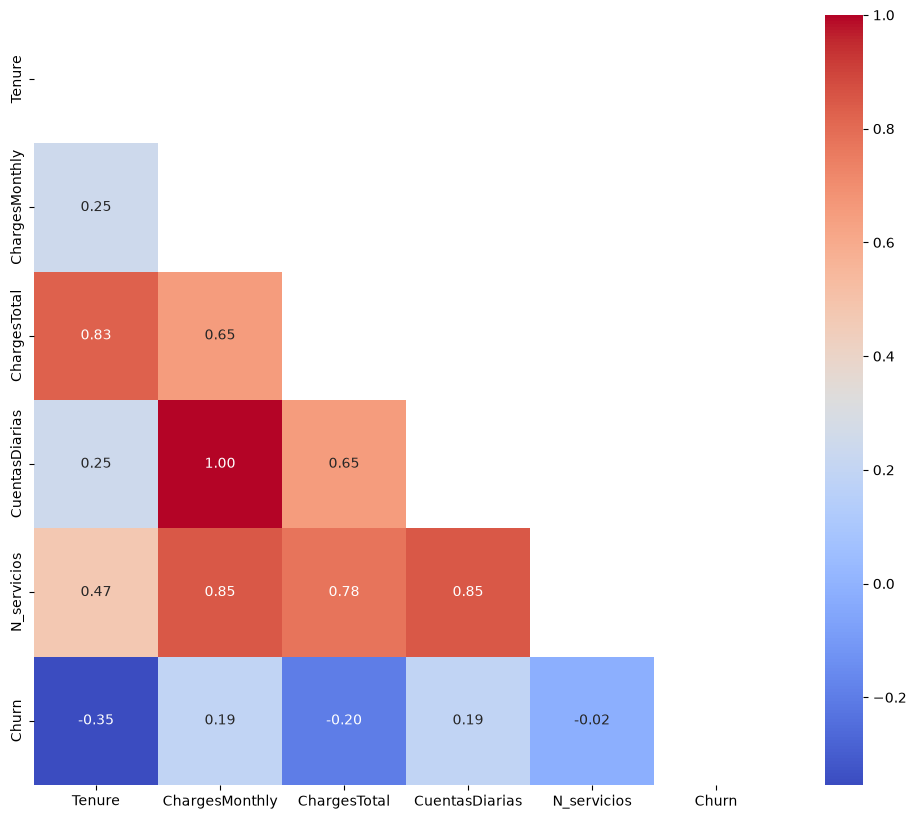

In [81]:
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df_corr, annot=True, cmap='coolwarm', fmt=".2f", mask=mascara_numericas, ax=ax)

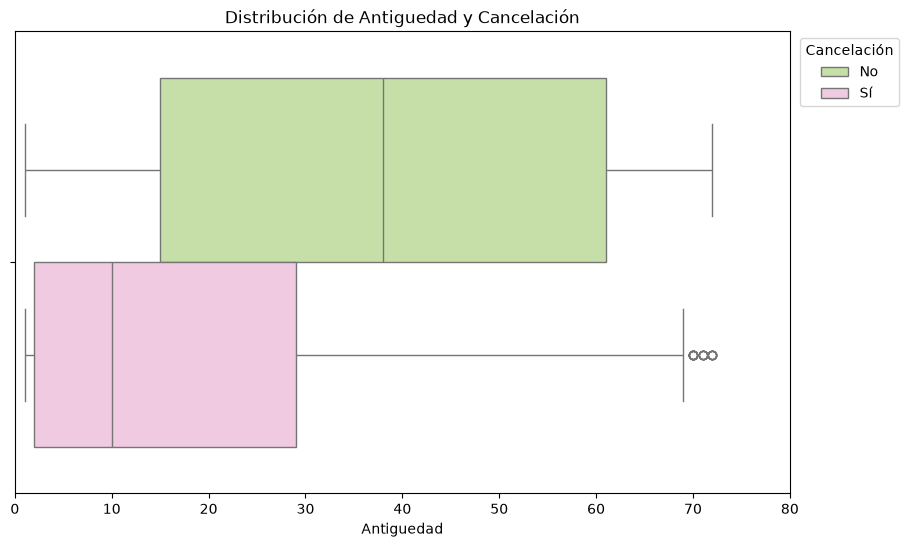

In [51]:
#Distribución de Tenure según si los clientes hiceron o no churn
fig, ax = plt.subplots(figsize=(10,6))
ax = sns.boxplot(data=variables_numericas, x='Tenure', hue='Churn', palette='PiYG_r')
ax.set_title('Distribución de Antiguedad y Cancelación')
ax.set_xlabel('Antiguedad')
ax.set_xlim(0,80)
ax.legend(title="Cancelación",labels=['No', 'Sí'], loc='best',  bbox_to_anchor=(1,0.70,0.15,0.3))

plt.show()

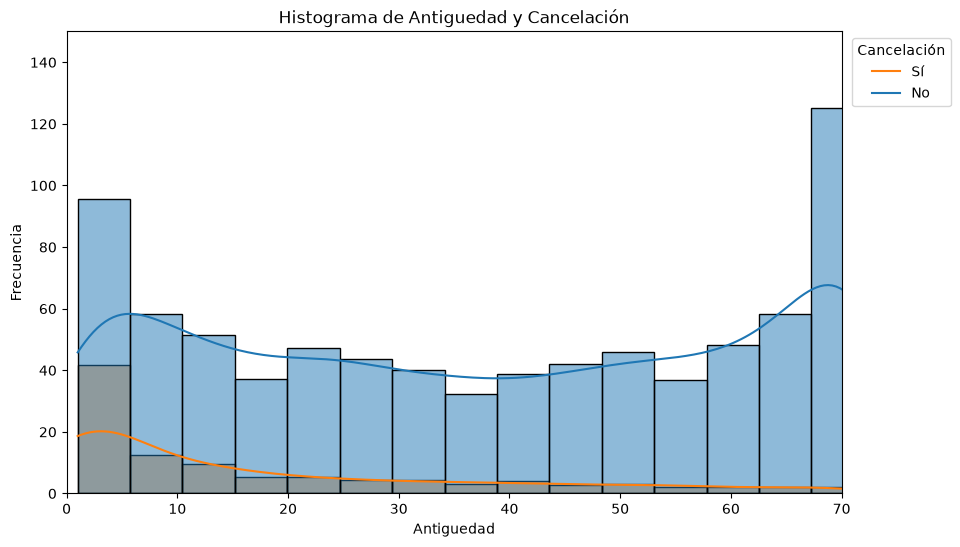

In [52]:
fig, ax = plt.subplots(figsize=(10,6))
ax = sns.histplot(variables_numericas,x='Tenure', hue='Churn', kde=True, stat='frequency')
ax.set_title('Histograma de Antiguedad y Cancelación')
ax.set_xlabel('Antiguedad')
ax.set_ylabel('Frecuencia')
ax.set_xlim(0,70)
ax.set_ylim(0,150)
ax.legend(title="Cancelación",labels=['Sí', 'No'], loc='upper right', bbox_to_anchor=(1,0.70,0.15,0.3))

plt.show()

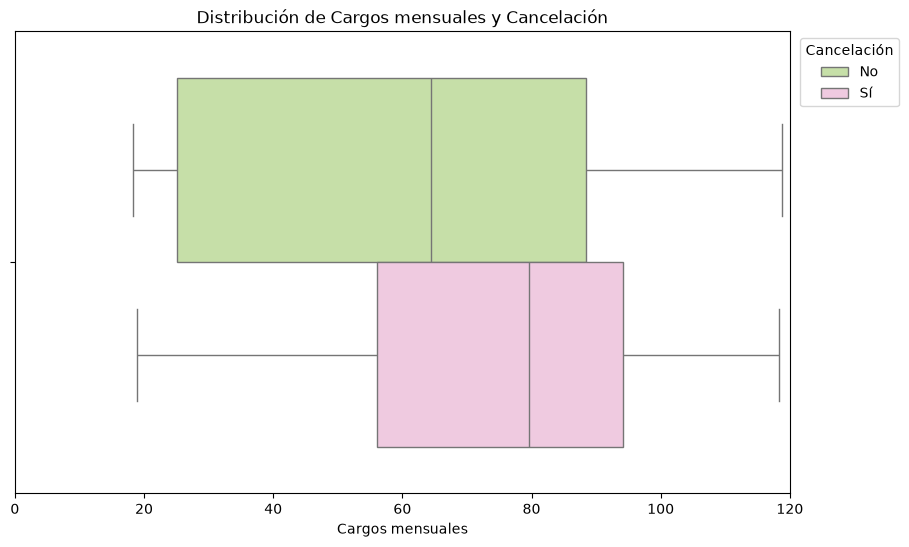

In [53]:
#Distribución de cargos mensuales según si los clientes hiceron o no churn
fig, ax = plt.subplots(figsize=(10,6))
ax = sns.boxplot(data=variables_numericas, x='ChargesMonthly', hue='Churn', palette='PiYG_r')
ax.set_title('Distribución de Cargos mensuales y Cancelación')
ax.set_xlabel('Cargos mensuales')
ax.set_xlim(0,120)
ax.legend(title="Cancelación",labels=['No', 'Sí'], loc='upper right', bbox_to_anchor=(1,0.70,0.15,0.3))

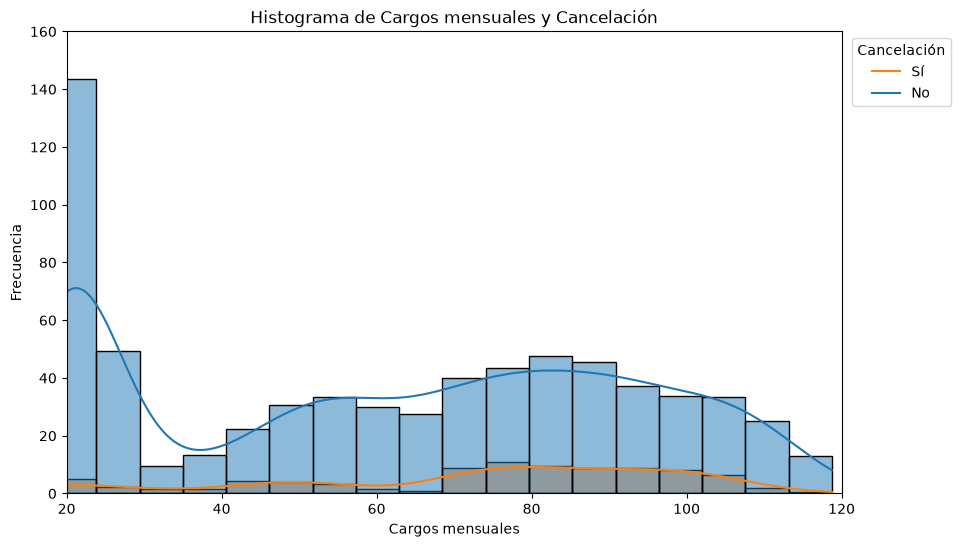

In [54]:
fig, ax = plt.subplots(figsize=(10,6))
sns.histplot(variables_numericas,x='ChargesMonthly', hue='Churn',kde=True, stat='frequency')
ax.set_title('Histograma de Cargos mensuales y Cancelación')
ax.set_xlabel('Cargos mensuales')
ax.set_ylabel('Frecuencia')
ax.set_xlim(20,120)
ax.set_ylim(0,160)
ax.legend(title="Cancelación",labels=['Sí', 'No'], loc='upper right', bbox_to_anchor=(1,0.70,0.15,0.3))

plt.show()

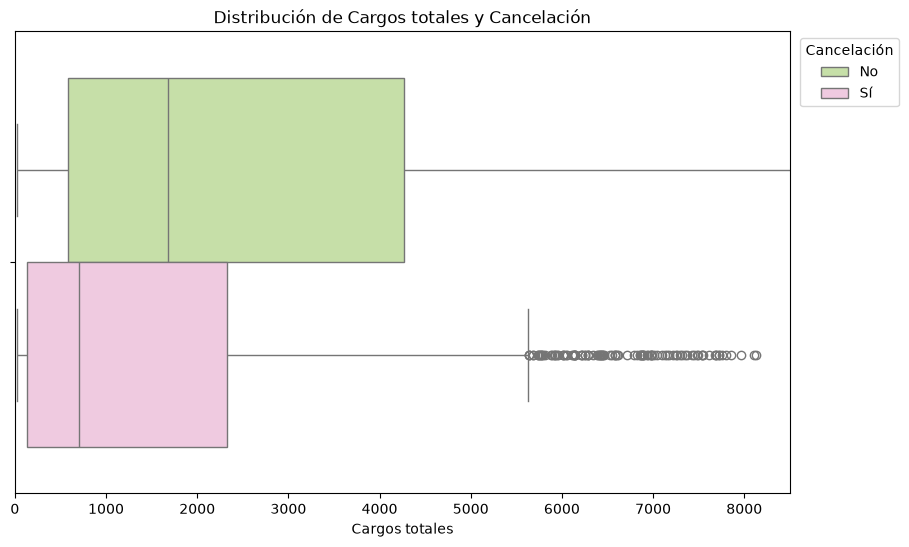

In [55]:
fig, ax = plt.subplots(figsize=(10,6))
ax = sns.boxplot(data=variables_numericas, x='ChargesTotal', hue='Churn', palette='PiYG_r')
ax.set_title('Distribución de Cargos totales y Cancelación')
ax.set_xlabel('Cargos totales')
ax.set_xlim(0,8500)
ax.legend(title="Cancelación",labels=['No', 'Sí'], loc='upper right', bbox_to_anchor=(1,0.70,0.15,0.3))

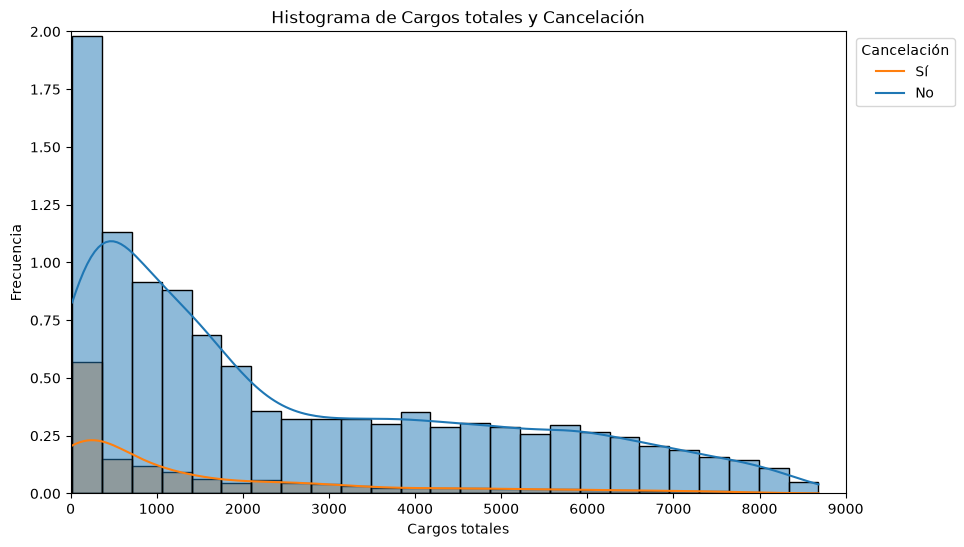

In [56]:
fig, ax = plt.subplots(figsize=(10,6))
sns.histplot(variables_numericas,x='ChargesTotal', hue='Churn',kde=True, stat='frequency')
ax.set_title('Histograma de Cargos totales y Cancelación')
ax.set_xlabel('Cargos totales')
ax.set_ylabel('Frecuencia')
ax.set_xlim(0,9000)
ax.set_ylim(0,2)
ax.legend(title="Cancelación",labels=['Sí', 'No'], loc='upper right', bbox_to_anchor=(1,0.70,0.15,0.3))
plt.show()

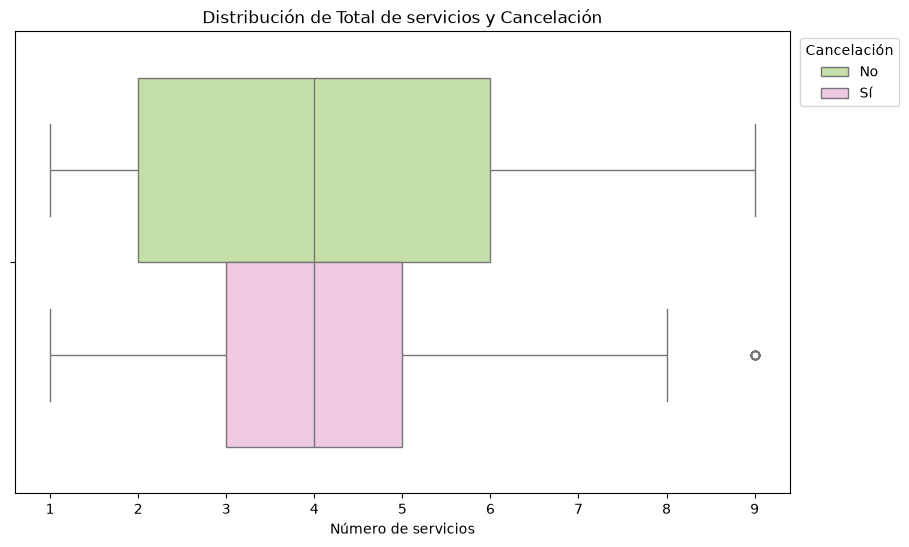

In [57]:
fig, ax = plt.subplots(figsize=(10,6))
ax = sns.boxplot(data=variables_numericas, x='N_servicios', hue='Churn', palette='PiYG_r')
ax.set_title('Distribución de Total de servicios y Cancelación')
ax.set_xlabel('Número de servicios')
#ax.set_xlim(0,8500)
ax.legend(title="Cancelación",labels=['No', 'Sí'], loc='upper right', bbox_to_anchor=(1,0.70,0.15,0.3))

In [58]:
#Filtro para separar los clientes que han cancelado
churn = variables_numericas['Churn'] == 1
#Creamos un dataframe con las variables que presentan datos atípicos
df_atipicos = variables_numericas[['Tenure', 'ChargesTotal','N_servicios', 'Churn']]
#Acá aplicamos el filtro anterior para quedarnos con los datos de los clientes que han hecho churn
df_atipicos = df_atipicos[churn]

In [59]:

variables_numericas['Churn'].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

In [60]:
indices_eliminar = []

In [61]:
#Definimos los límites superior e inferior para identificar los valores atípicos en Tenure
q1, q3 = np.percentile(df_atipicos['Tenure'], [25,75])
ric = q3 - q1
ten_inferior = q1 - (1.5 * ric)
ten_superior = q3 + (1.5 * ric)
#Guaramos los indices de los valores atípicos identificados
indice_atipicos_ten = df_atipicos[(df_atipicos['Tenure'] < ten_inferior) | (df_atipicos['Tenure'] > ten_superior)].index
indice_atipicos_ten

Index([ 115,  514,  625,  994, 1066, 1333, 1514, 1738, 1958, 2003, 2282, 2453,
       2730, 3175, 3425, 3752, 4285, 4648, 4828, 5079, 5199, 6055, 6230],
      dtype='int64')

In [62]:
#Los indices los guardAmos en la lista indices_eliminar
indices_eliminar.extend(indice_atipicos_ten)

In [63]:
#Contamos la cantidad de datos a eliminar
len(indices_eliminar)

23

In [64]:
#Definimos los límites superior e inferior para identificar los valores atípicos en Charges total
q1, q3 = np.percentile(df_atipicos['ChargesTotal'], [25,75])
ric = q3 - q1
charges_inferior = q1 - (1.5 * ric)
charges_superior = q3 + (1.5 * ric)
#Guaramos los indices de los valores atípicos identificados
indice_atipicos_char = df_atipicos[(df_atipicos['ChargesTotal'] < charges_inferior) | (df_atipicos['ChargesTotal'] > charges_superior)].index
len(indice_atipicos_char)

109

In [65]:
#Los indices los guardmos en la lista indices_eliminar
indices_eliminar.extend(indice_atipicos_char)

In [66]:
#Contamos la cantidad de datos a eliminar
len(indices_eliminar)

132

In [67]:
#Definimos los límites superior e inferior para identificar los valores atípicos en Tenure
q1, q3 = np.percentile(df_atipicos['N_servicios'], [25,75])
ric = q3 - q1
servicios_inferior = q1 - (1.5 * ric)
servicios_superior = q3 + (1.5 * ric)
#Guaramos los indices de los valores atípicos identificados
indice_atipicos_ser = df_atipicos[(df_atipicos['N_servicios'] < servicios_inferior) | (df_atipicos['N_servicios'] > servicios_superior)].index
indice_atipicos_ser

Index([115, 994, 1066, 1579, 2003, 3046, 3742, 5824, 6055, 6389, 6470], dtype='int64')

In [68]:
len(indice_atipicos_ser)

11

In [69]:
indices_eliminar.extend(indice_atipicos_ser)

In [70]:
#Nos aseguramos que los indices no se repitan
indices_eliminar = list(set(indices_eliminar))
len(indices_eliminar)

116

In [71]:
#Eliminamos los indices de los valores atípicos del df variables_numericas y
#guardamos los resultados en otro df llamado df_limpio
df_limpio = variables_numericas.drop(indices_eliminar)

In [72]:
df_limpio['Churn'].value_counts(normalize=True)

Churn
0    0.74653
1    0.25347
Name: proportion, dtype: float64

In [73]:
df_limpio.columns

Index(['Tenure', 'ChargesMonthly', 'ChargesTotal', 'CuentasDiarias',
       'N_servicios', 'Churn'],
      dtype='str')

<Axes: xlabel='Tenure'>

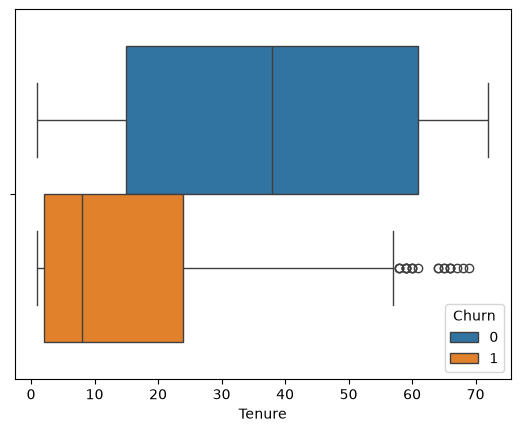

In [74]:
sns.boxplot(data=df_limpio, x='Tenure', hue='Churn')

<Axes: xlabel='Tenure', ylabel='Frequency'>

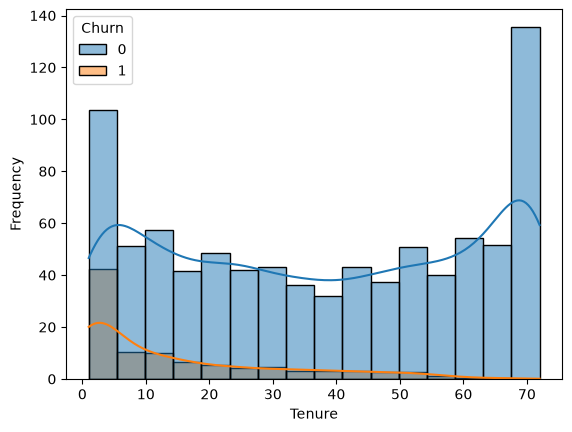

In [75]:
"""
Verificación de la distribución de Tenure y Churn después de elimnar los
valores atípicos
"""
sns.histplot(df_limpio,x='Tenure', hue='Churn',kde=True, stat='frequency')

<Axes: xlabel='ChargesTotal'>

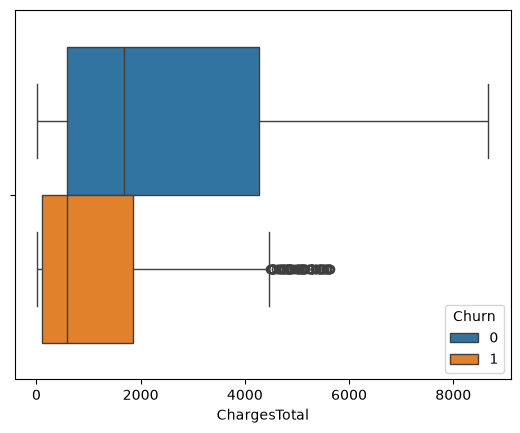

In [76]:
"""
Verificación de la distribución de Charges total y Churn después de elimnar los
valores atípicos
"""
sns.boxplot(data=df_limpio, x='ChargesTotal', hue='Churn')
     

<Axes: xlabel='ChargesTotal', ylabel='Frequency'>

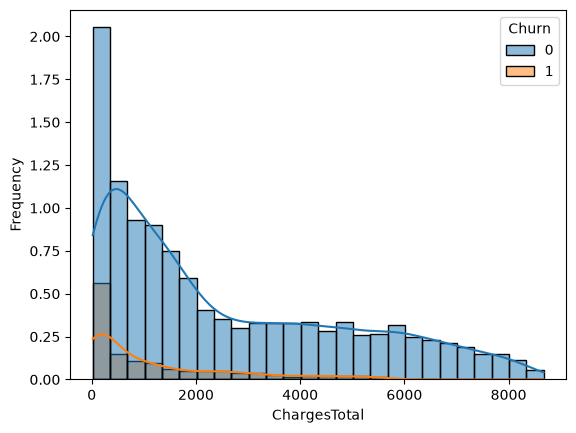

In [77]:
"""
Verificación de la distribución de Charges total y Churn después de elimnar los
valores atípicos
"""
sns.histplot(df_limpio,x='ChargesTotal', hue='Churn',kde=True, stat='frequency')

<Axes: xlabel='N_servicios'>

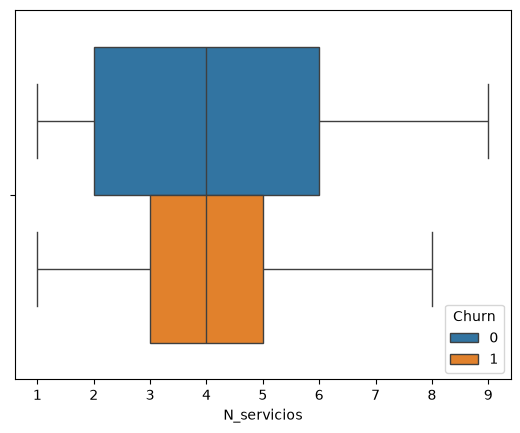

In [78]:
sns.boxplot(data=df_limpio, x='N_servicios', hue='Churn')

In [79]:
"""
Correlación entre las variables numéricas despúes de eliminar
los valores atípicos
"""
df_limpio[['Tenure', 'ChargesMonthly','ChargesTotal', 'N_servicios', 'Churn']].corr()

,Tenure,ChargesMonthly,ChargesTotal,N_servicios,Churn
Tenure,1.000000,0.227007,0.822031,0.461851,-0.404531
ChargesMonthly,0.227007,1.000000,0.638861,0.847658,0.163930
ChargesTotal,0.822031,0.638861,1.000000,0.772188,-0.266006
N_servicios,0.461851,0.847658,0.772188,1.000000,-0.056176
Churn,-0.404531,0.163930,-0.266006,-0.056176,1.000000
